In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn. linear_model import LinearRegression, Lasso


In [2]:
df = pd.read_csv('hotel_bookings.csv')
df.drop_duplicates()
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [3]:
num_cols = df.select_dtypes(include =['int64', 'float64']).columns
cate_cols = df.select_dtypes(include = ['object']).columns

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())


for col in cate_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [4]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

In [5]:
num_cols = df.select_dtypes(include =['int64', 'float64']).columns.tolist()
cate_cols = df.select_dtypes(include = ['object']).columns.tolist()


num_cols univriate


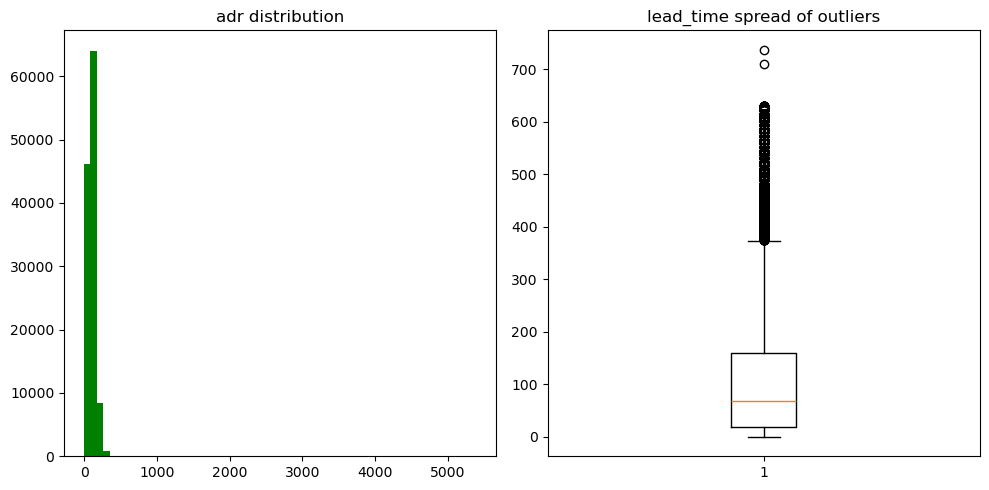

In [6]:
fig , axes = plt.subplots(1,2 , figsize = (10,5))
axes[0].hist(df['adr'], bins =60, color = 'Green')
axes[0].set_title('adr distribution')


axes[1].boxplot(df['lead_time'], vert = True)
axes[1].set_title('lead_time spread of outliers')
print('num_cols univriate')
plt.tight_layout()
plt.show()
plt.close()

cate_cols univariate


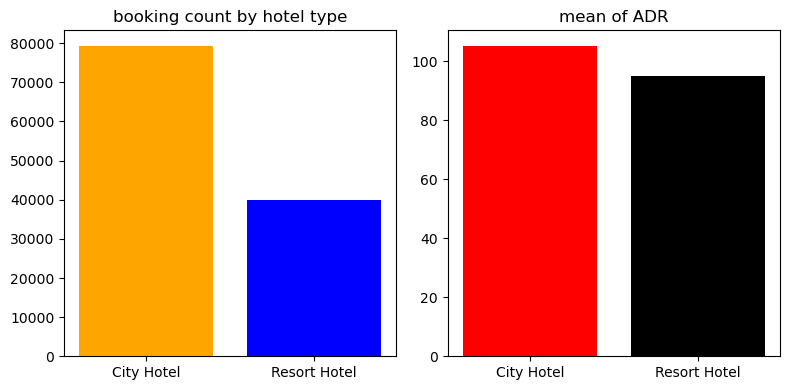

In [7]:
fig, axes = plt.subplots(1, 2 , figsize = (8,4))
hotel_counts = df['hotel'].value_counts()
axes[0].bar(hotel_counts.index , hotel_counts.values , color = ['Orange' , 'Blue'])
axes[0].set_title('booking count by hotel type')

mean_adr = df.groupby('hotel')['adr'].mean()

axes[1].bar(mean_adr.index , mean_adr.values , color = ['Red' , 'Black'])
axes[1].set_title('mean of ADR')
print('cate_cols univariate')
plt.tight_layout()
plt.show()
plt.close()

num vs num


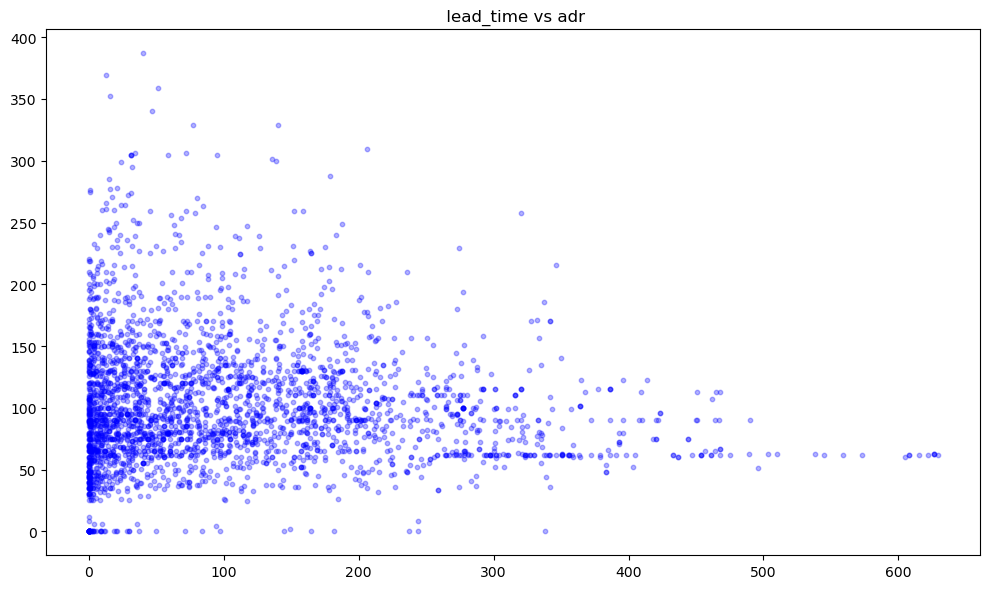

In [8]:
print('num vs num')
fig , ax = plt.subplots(figsize = (10,6))

sample = df.sample(3000, random_state = 1)
ax.scatter(sample['lead_time'],sample['adr'],alpha = 0.3 , s = 10 , color = 'Blue')
ax.set_title(' lead_time vs adr')
plt.tight_layout()
plt.show()
plt.close()

seaborn numcols


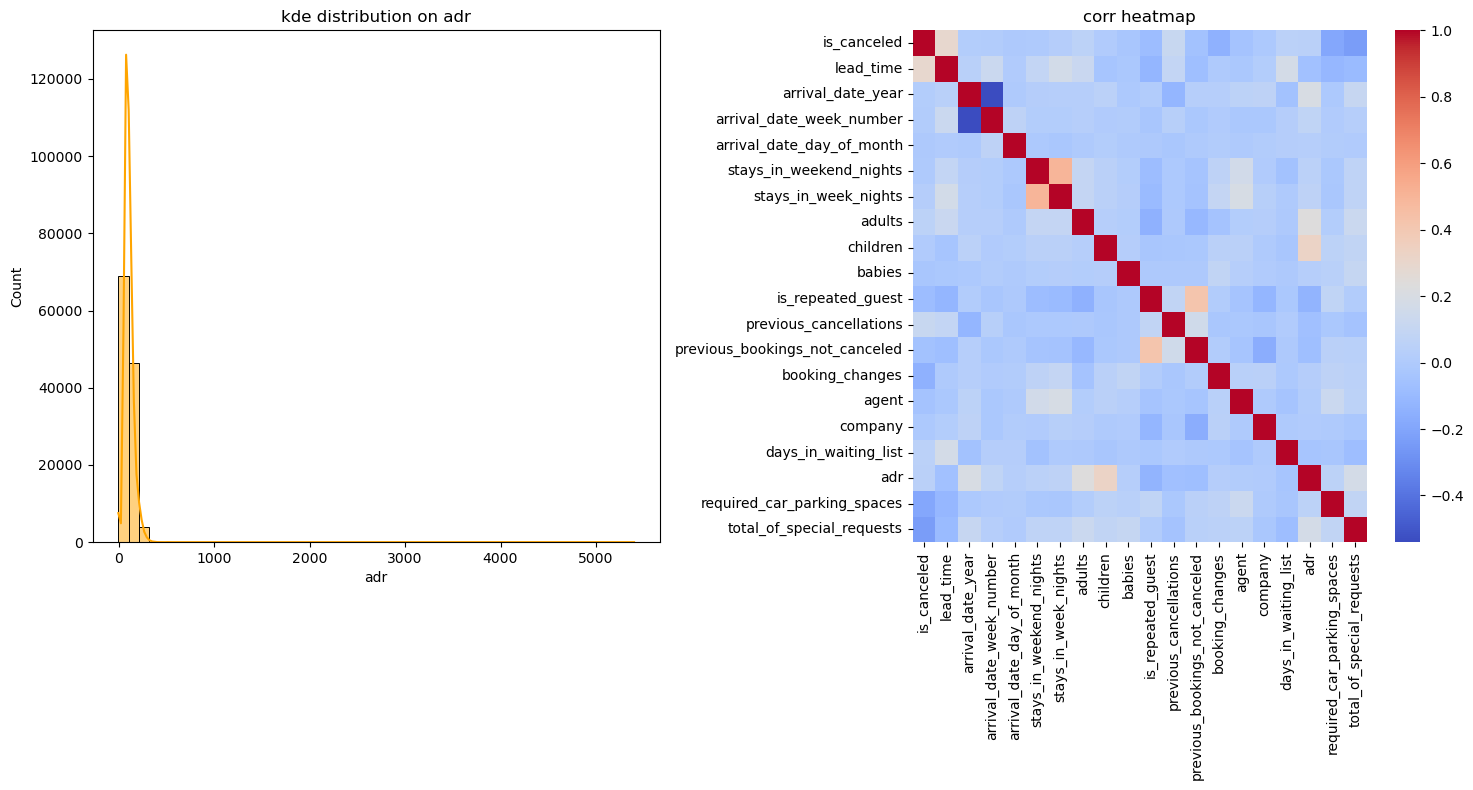

In [9]:
print('seaborn numcols')
fig , axes = plt.subplots(1,2, figsize = (15, 8))
sns.histplot(df['adr'], bins = 50 , kde = True, ax=axes[0], color = 'Orange')
axes[0].set_title('kde distribution on adr')

corr = df[num_cols].corr()
sns.heatmap(corr, cmap = 'coolwarm' , ax = axes[1] )
axes[1].set_title('corr heatmap')

plt.tight_layout()
plt.show()
plt.close()


seaborn cate_cols


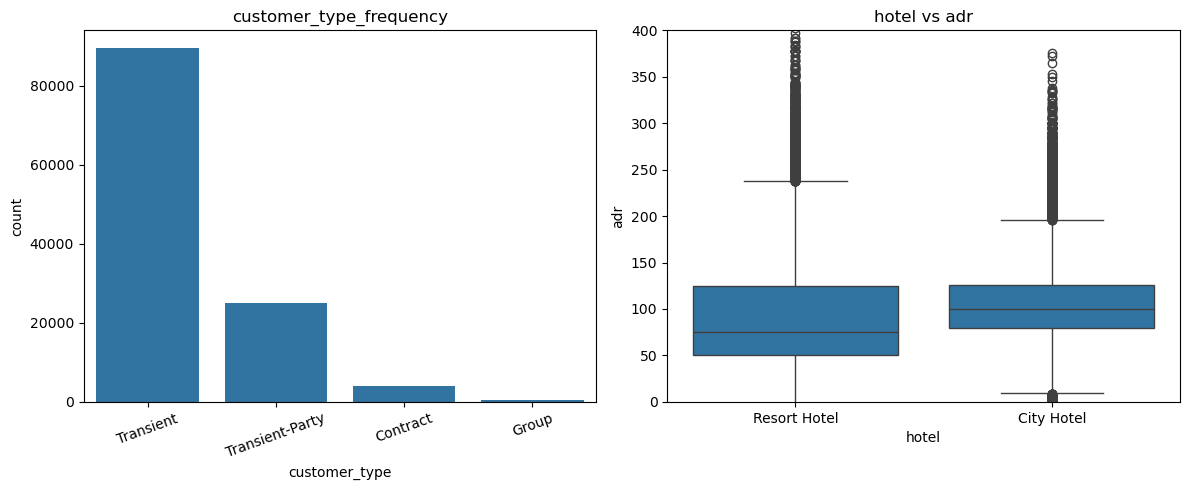

In [10]:
print('seaborn cate_cols')
fig , axes = plt.subplots(1,2, figsize = (12,5))

sns.countplot(data = df , x = 'customer_type' , ax= axes[0],
              order = df['customer_type'].value_counts().index)
axes[0].set_title('customer_type_frequency')
axes[0].tick_params(axis = 'x', rotation = 20)

sns.boxplot(data=df, x = 'hotel', y = 'adr', ax = axes[1])
axes[1].set_title('hotel vs adr')
axes[1].set_ylim(0,400)

plt.tight_layout()
plt.show()
plt.close()

C:\Users\adith\AppData\Local\Temp\ipykernel_21264\3758604749.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data= df, x = 'arrival_date_month', y= 'adr', order = months, ax= ax, palette = 'coolwarm')


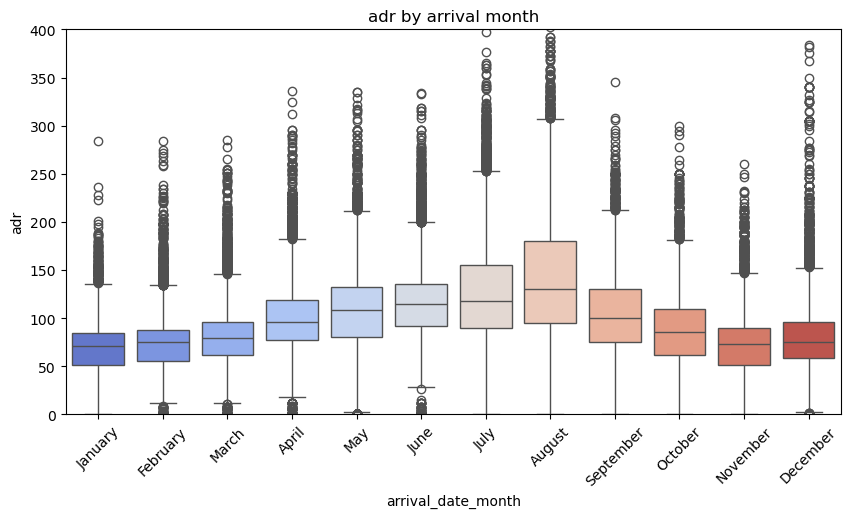

In [11]:
fig ,ax = plt.subplots(figsize = (10,5))

months = ['January' , 'February','March' ,'April', 'May', 'June', 'July', 
          'August', 'September', 'October', 'November', 'December']
sns.boxplot(data= df, x = 'arrival_date_month', y= 'adr', order = months, ax= ax, palette = 'coolwarm')
ax.set_title('adr by arrival month')
ax.set_ylim(0,400)
ax.tick_params(axis = 'x' , rotation = 45)

plt.show()
plt.tight_layout()
plt.close()

In [12]:
X = df.drop(columns = 'adr')
y = df['adr']
X = X.drop(columns = ['reservation_status_date'],errors = 'ignore')


In [13]:
X_train, X_test, y_train, y_test = train_test_split (X,y,test_size=0.3, random_state=42)

In [14]:
df[num_cols].skew()

is_canceled                        0.536678
lead_time                          1.346550
arrival_date_year                 -0.232583
arrival_date_week_number          -0.010014
arrival_date_day_of_month         -0.002000
stays_in_weekend_nights            1.380046
stays_in_week_nights               2.862249
adults                            18.317805
children                           4.112670
babies                            24.646545
is_repeated_guest                  5.326315
previous_cancellations            24.458049
previous_bookings_not_canceled    23.539800
booking_changes                    6.000270
agent                              1.314456
company                            3.417783
days_in_waiting_list              11.944353
adr                               10.530214
required_car_parking_spaces        4.163233
total_of_special_requests          1.349189
dtype: float64

In [15]:
heavy = ['lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults',
         'children', 'babies', 'booking_changes', 'days_in_waiting_list',
         'required_car_parking_spaces', 'total_of_special_requests']
for col in heavy:
    q1,q3 = X_train[col].quantile([0.25,0.75])
    iqr = q3 -q1
    lower,upper = q1-1.5 * iqr , q3 + 1.5*iqr
    X_train[col] = X_train[col].clip(lower,upper)
    X_test[col] = X_test[col].clip(lower,upper)
    

In [16]:
X_train = pd.get_dummies(X_train, drop_first = True, dtype = int)
X_test = pd.get_dummies(X_test , drop_first = True, dtype = int)
X_train, X_test = X_train.align(X_test , join = 'left', axis = 1, fill_value = 0)


In [17]:
scaler = StandardScaler()

x_train = scaler.fit_transform(X_train)
x_test = scaler.transform(X_test)

In [18]:
models = { 
    'linear' : LinearRegression(),
    'lasso' : Lasso(alpha= 0.1, max_iter = 2999, random_state = 42),
    'decision_tree' : DecisionTreeRegressor(max_depth = 12, min_samples_split=20, random_state = 42),
    'randomforest' : RandomForestRegressor(n_estimators = 80, max_features = 0.4, max_depth = 15, n_jobs = -1, random_state = 42),

}


In [19]:
for name, model in models.items():
    xtr, xts = (x_train,x_test) if name in ('linear', 'lasso') else (X_train, X_test)
    model.fit(xtr, y_train)
    pred = model.predict(xts)


    print(f'-----{name}-----')
    print(f'r2 : {r2_score(y_test, pred) :.2f}')
    print(f'mae: {mean_absolute_error(y_test, pred) :.2f}')
    print(f'mse: {mean_squared_error(y_test, pred) :.2f}')
    print(f'rmse: {np.sqrt(mean_squared_error(y_test, pred)) :.3f}')
    

-----linear-----
r2 : 0.60
mae: 22.11
mse: 922.43
rmse: 30.371
-----lasso-----
r2 : 0.60
mae: 22.09
mse: 923.73
rmse: 30.393
-----decision_tree-----
r2 : 0.74
mae: 16.13
mse: 609.71
rmse: 24.692
-----randomforest-----
r2 : 0.84
mae: 12.08
mse: 368.19
rmse: 19.188


In [20]:
rf_grid = {
    'n_estimators' : [25,45,50],
    'max_depth' : [12, 25, 30],
}

grid = GridSearchCV(RandomForestRegressor(n_jobs= -1, random_state = 42),
                    param_grid = rf_grid, cv=5, scoring = 'r2', n_jobs = -1)
grid.fit(X_train, y_train)
print(grid.best_params_ , round(grid.best_score_, 3))

best_pred = grid.best_estimator_.predict(X_test)
print('final socre:' , round(r2_score(y_test, best_pred), 4))

{'max_depth': 30, 'n_estimators': 50} 0.796
final socre: 0.8765


In [21]:
dt_grid = {
    'max_depth': [5,25,40],
    'min_samples_split' : [2,10,15],
    'min_samples_leaf': [ 2,5,9],
    'max_features': [None , 'sqrt', 'log2']
}

grid = GridSearchCV(
    estimator = DecisionTreeRegressor(random_state =42),
    param_grid = dt_grid, cv = 5, scoring = 'r2', n_jobs = -1, verbose = 1)

grid.fit(X_train, y_train)
print(grid.best_params_ , round(grid.best_score_,3))

best_pred = grid.best_estimator_.predict(X_test)
print('final_score:' , round(r2_score(y_test, best_pred) , 3))


Fitting 5 folds for each of 81 candidates, totalling 405 fits
{'max_depth': 40, 'max_features': None, 'min_samples_leaf': 9, 'min_samples_split': 2} 0.725
final_score: 0.784


In [22]:
from sklearn.model_selection import RandomizedSearchCV
rf_rand = {
    'n_estimators' : [25,45,60,80],'max_depth' : [12, 25, 30,40],
}
rand_rf = RandomizedSearchCV(RandomForestRegressor(n_jobs= -1, random_state = 42),param_distributions = rf_rand, cv=5, scoring = 'r2', n_jobs = -1)
rand_rf.fit(X_train, y_train)
print(rand_rf.best_params_ , round(rand_rf.best_score_, 3))
best_pred = rand_rf.best_estimator_.predict(X_test)
print('final socre:' , round(r2_score(y_test, best_pred), 4))

{'n_estimators': 60, 'max_depth': 40} 0.797
final socre: 0.8765


In [28]:
dt_rand = {'max_depth': [5,25,30],'min_samples_split' : [2,10,15],'min_samples_leaf': [ 2,5,9],'max_features': [None , 'sqrt', 'log2']
}
rand_decisions = RandomizedSearchCV(estimator = DecisionTreeRegressor(random_state =42),param_distributions = dt_rand, cv = 6, scoring = 'r2', n_jobs = -1, verbose = 1)
rand_decisions.fit(X_train, y_train)
print(rand_decisions.best_params_ , round(rand_decisions.best_score_3))
best_pred = rand_decisions.best_estimator_.predict(X_test)
print('final_score:' , round(r2_score(y_test, best_pred) , 3))


Fitting 6 folds for each of 10 candidates, totalling 60 fits


AttributeError: 'RandomizedSearchCV' object has no attribute 'best_score_3'